In [ ]:
! pip install ucimlrepo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

In [ ]:
def inv_map(lst: list):
  return {j:i for i,j in enumerate(lst)}

def process_adult_dataset():
  adult = fetch_ucirepo(id=2)

  X = adult.data.features
  y = adult.data.targets

  # cleaning columns
  df = pd.DataFrame(X)
  df['target'] = y.map(lambda p: p[:-1] if p.endswith('.') else p)

  # removing duplicates
  print(df['target'].value_counts())
  df = df.dropna()
  df.drop_duplicates(inplace=True)
  print(df['target'].value_counts())

  # Label Encoding
  categorical = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
  for i in categorical:
    uniques = df[i].unique()
    df[i] = df[i].map(inv_map(uniques))
  df['target'] = df['target'].map({
      '<=50K': 0,
      '>50K': 1
  })

  return df

In [ ]:
def process_churn_dataset():
  df = pd.read_csv('/content/drive/MyDrive/Offline 2 Data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
  del df['customerID']

  categorical = ['gender', 'InternetService', 'Contract', 'PaymentMethod']

  yes_no = ['Partner', 'Dependents', 'PhoneService','MultipleLines', 'OnlineSecurity',
            'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
            'StreamingMovies', 'PaperlessBilling', 'Churn'
            ]

  for i in yes_no:
    df[i] = df[i].map({
        'Yes': 1,
        'No' : 0,
        'No internet service': -1,
        'No phone service': -1
    })

  for i in categorical:
    df[i] = df[i].map(inv_map(df[i].unique()))

  df = df.rename(columns={'Churn': 'target'})

  df = df.drop_duplicates()
  df.loc[df['TotalCharges'] == ' '] = 0

  return df

In [ ]:
df = process_churn_dataset()
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,target
0,0,0,1,0,1,0,-1,0,0,1,0,0,0,0,0,1,0,29.85,29.85,0
1,1,0,0,0,34,1,0,0,1,0,1,0,0,0,1,0,1,56.95,1889.5,0
2,1,0,0,0,2,1,0,0,1,1,0,0,0,0,0,1,1,53.85,108.15,1
3,1,0,0,0,45,0,-1,0,1,0,1,1,0,0,1,0,2,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,0,70.70,151.65,1


In [ ]:
df = process_adult_dataset()
df.head()

target
<=50K    37155
>50K     11687
Name: count, dtype: int64
target
<=50K    36038
>50K     11535
Name: count, dtype: int64


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,target
0,39,0,77516,0,13,0,0,0,0,0,2174,0,40,0,0
1,50,1,83311,0,13,1,1,1,0,0,0,0,13,0,0
2,38,2,215646,1,9,2,2,0,0,0,0,0,40,0,0
3,53,2,234721,2,7,1,2,1,1,0,0,0,40,0,0
4,28,2,338409,0,13,1,3,2,1,1,0,0,40,1,0


## Data Prep

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler

In [ ]:
X, y = df.drop('target', axis=1), df['target']
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=42)
train_x, val_x, train_y, val_y = train_test_split(train_x, train_y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
train_x = scaler.fit_transform(train_x)
test_x = scaler.transform(test_x)
val_x = scaler.transform(val_x)

In [ ]:
train_xs = []
train_ys = []

for i in range(9):
  tx, ty= resample(train_x, train_y, n_samples=len(train_x)//9, random_state=42 + i, stratify=train_y)
  train_xs.append(tx.copy())
  train_ys.append(ty.copy())

## Modelling

In [ ]:
from sklearn.linear_model import LogisticRegression
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix

In [ ]:
class MyLogisticRegression:
  def __init__(self, lr=0.01, epochs=1000):
    self.lr = lr
    self.epochs = epochs
    self.weights = None
    self.bias = None
    self.history = []

  def predict(self, X):
    y_pred = self.predict_proba(X)
    return np.where(y_pred >= 0.5, 1, 0)

  def predict_proba(self, X):
    z = np.dot(X, self.weights) + self.bias
    y_pred = self.activation(z)

    return y_pred

  def activation(self, z):
    return 1 / (1 + np.exp(-z))

  def fit(self, X, y):
    self.weights = np.zeros(X.shape[1])
    self.bias = 0
    self.history = []

    for i in range(self.epochs):
      y_pred = self.predict_proba(X)

      loss = -np.mean(
          y * np.log(y_pred) +
          (1 - y) * np.log(1 - y_pred)
      )

      self.weights -= self.lr * np.dot(X.T, y_pred - y) / X.shape[0]
      self.bias -= self.lr * np.mean(y_pred - y)

      self.history.append(loss)


In [ ]:
models = []
for i in tqdm(range(9)):
  model = MyLogisticRegression(lr=.1)
  model.fit(train_xs[i], train_ys[i])
  models.append(model)

  0%|          | 0/9 [00:00<?, ?it/s]

In [ ]:
training = []
test = []
val = []
for i in range(5):
  traiing_acc = accuracy_score(train_ys[i], models[i].predict(train_xs[i]))
  training.append(traiing_acc)
  test_acc = accuracy_score(test_y, models[i].predict(test_x))
  test.append(test_acc)
  val_acc = accuracy_score(val_y, models[i].predict(val_x))
  val.append(val_acc)
pd.DataFrame({
    'Training': training,
    'Validation': val,
    'Test': test,
})

,Training,Validation,Test
0,0.829687,0.824750,0.820599
1,0.816085,0.823568,0.817867
2,0.817268,0.822517,0.818917
3,0.830869,0.822386,0.817551
4,0.820225,0.824619,0.818707


<Axes: >

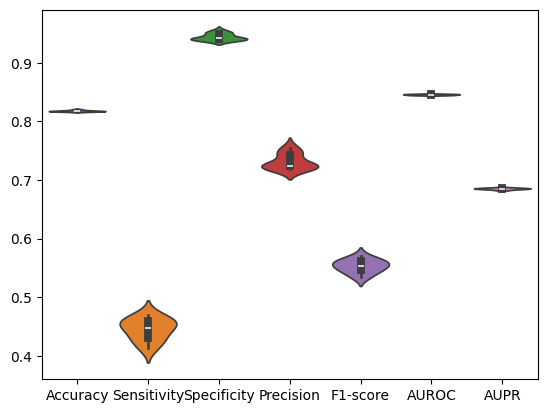

In [ ]:
def evaluate_model(y_gt, y_proba):
  y_pred = y_proba >= 0.5

  accuracy = accuracy_score(y_gt, y_pred)
  precision = precision_score(y_gt, y_pred)
  recall = recall_score(y_gt, y_pred)
  f1 = f1_score(y_gt, y_pred)
  roc_auc = roc_auc_score(y_gt, y_proba)
  aupr = average_precision_score(y_gt, y_proba)

  sensitivity = recall
  tn, fp, fn, tp = confusion_matrix(y_gt, y_pred).ravel()
  specificity = tn / (tn + fp)

  return {
      'Accuracy': accuracy,
      'Sensitivity': sensitivity,
      'Specificity': specificity,
      'Precision': precision,
      'F1-score': f1,
      'AUROC': roc_auc,
      'AUPR': aupr
  }

all_metrics = []

for i in range(9):
  y_pred = models[i].predict_proba(test_x)
  metrics = evaluate_model(test_y, y_pred)
  metrics['Model'] = f'Model {i+1}'
  all_metrics.append(metrics)

metrics_df = pd.DataFrame(all_metrics)
metrics_df.set_index('Model', inplace=True)
sns.violinplot(data=metrics_df)

## Ensembling

In [ ]:
preds_test = []
preds_val = []
for i in range(9):
  preds_test.append(models[i].predict(test_x))
  preds_val.append(models[i].predict(val_x))

preds_test = np.vstack(preds_test).T
preds_val = np.vstack(preds_val).T

### Majority Voting

In [ ]:
pred = preds_test.sum(axis=1) / 9
voting_metric = evaluate_model(test_y, pred)
voting_metric

{'Accuracy': 0.8178665265370467,
 'Sensitivity': 0.44167704441677047,
 'Specificity': 0.9453982549957782,
 'Precision': 0.7327823691460055,
 'F1-score': 0.5511525511525511,
 'AUROC': 0.7240338936792639,
 'AUPR': 0.5187472095585604}

### Stacking

In [ ]:
meta_model = MyLogisticRegression()
meta_model.fit(preds_val, val_y)

In [ ]:
pred = meta_model.predict_proba(preds_test)
stacking_metric = evaluate_model(test_y, pred)
stacking_metric

{'Accuracy': 0.8179716237519705,
 'Sensitivity': 0.4167704441677044,
 'Specificity': 0.9539825499577822,
 'Precision': 0.754320060105184,
 'F1-score': 0.5368983957219251,
 'AUROC': 0.7240595678766778,
 'AUPR': 0.5195077142520106}

# Reporting

In [ ]:
lr_metrics = metrics_df.mean().to_dict()
lr_metrics['Method'] = 'LR'
lr_metrics['Accuracy'] = f"{lr_metrics['Accuracy']:.3f} ± {metrics_df['Accuracy'].std():.3f}"
lr_metrics['Sensitivity'] = f"{lr_metrics['Sensitivity']:.3f} ± {metrics_df['Sensitivity'].std():.3f}"
lr_metrics['Specificity'] = f"{lr_metrics['Specificity']:.3f} ± {metrics_df['Specificity'].std():.3f}"
lr_metrics['Precision'] = f"{lr_metrics['Precision']:.3f} ± {metrics_df['Precision'].std():.3f}"
lr_metrics['F1-score'] = f"{lr_metrics['F1-score']:.3f} ± {metrics_df['F1-score'].std():.3f}"
lr_metrics['AUROC'] = f"{lr_metrics['AUROC']:.3f} ± {metrics_df['AUROC'].std():.3f}"
lr_metrics['AUPR'] = f"{lr_metrics['AUPR']:.3f} ± {metrics_df['AUPR'].std():.3f}"


report_df = pd.DataFrame([
    lr_metrics,
    {'Method': 'Majority Voting', **voting_metric},
    {'Method': 'Stacking', **stacking_metric}
])
report_df = report_df.set_index('Method')
report_df

,Accuracy,Sensitivity,Specificity,Precision,F1-score,AUROC,AUPR
Method,,,,,,,
LR,0.818 ± 0.001,0.445 ± 0.019,0.944 ± 0.006,0.731 ± 0.013,0.553 ± 0.011,0.846 ± 0.001,0.685 ± 0.001
Majority Voting,0.817867,0.441677,0.945398,0.732782,0.551153,0.724034,0.518747
Stacking,0.817972,0.41677,0.953983,0.75432,0.536898,0.72406,0.519508
